In [1]:
import os, sys, shutil
from tqdm import tqdm
import numpy as np
import pandas as pd
# Set the display options to show all columns
pd.set_option('display.max_columns', None)
from PIL import Image
from matplotlib.lines import Line2D
import matplotlib.pyplot as plt
import math
import random
from datetime import datetime
from scipy.stats import binomtest
from collections import defaultdict
experiment_version = 2
response_version = 1

stimuli_path = f"stimuli_v{experiment_version}/"
response_path = f"responses_v{experiment_version}/"
dataframe_path = f"dataframes_v{experiment_version}/"

os.makedirs(stimuli_path, exist_ok=True)
os.makedirs(response_path, exist_ok=True)
os.makedirs(dataframe_path, exist_ok=True)

# CREATE EXPERIMENT DATAFRAME AND TRIAL FILES FOR MEADOWS

In [2]:

#Experiment column key:
# 1: Experiment 1, GT experiment to compare similarity scores of recons with varying strength parameters
df_exp = pd.DataFrame(columns=["experiment", "stim1", "stim2", "stim3", "stim4", "stim2_str", "stim3_str", "stim4_str", "shuffle_vdvae", "target_on_left", "method", "catch_trial", "sample", "subject",  "rep", "mode", "stimtype"])
i=0
strength_values = [0.0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1]
stimuli_root = "/export/raid1/home/kneel027/nsd_imagery_journal_paper/reconstructions/"
gt_root = "/export/raid1/home/kneel027/data/umn-imagery/nsddata_stimuli/stimuli/imagery_images/"
method = "braindiffuser_augmentations"
mode="gt"
for sample in tqdm(range(12)):
    gt_sample = f"{sample}_ground_truth"
    gt_sample_path = f"{gt_root}/{sample}.png"
    gt_image = Image.open(gt_sample_path).resize((512,512))
    gt_image.save(f"stimuli_v{experiment_version}/{gt_sample}.png")
    
    if sample <6:
        stimtype = "simple"
    elif sample < 12:
        stimtype = "complex"
    else:
        stimtype = "concept"
    
    for shuffle_vdvae, augment_params, augment_tag in [(False, "-str_0.4-mix_gt", ""), (True, "-str_0.4-mix_gt_shuffle-vdvae", "_sv")]:
        candidate_stimuli = []
        for rep in range(10):
            for strength in strength_values:
                candidate_stimuli.append((strength, rep))
        random.shuffle(candidate_stimuli)
        while len(candidate_stimuli) > 2:
            stimuli = []
            for stim in range(2,5):
                strength, rep = candidate_stimuli.pop()
                stim_tag = f"{sample}_gt_recon_{rep}_{strength}{augment_tag}"
                stimuli.append((stim_tag, strength, rep))
            
                # Load the stimulus images and save as pngs to stimuli folder
                stim_recon_path = f"{stimuli_root}vision/{method}/{strength:.1f}{augment_params}/subject1/{sample}/{rep}.png"
            
                # Copy the stimulus images to the stimuli folder
                shutil.copy(stim_recon_path, f"stimuli_v{experiment_version}/{stim_tag}.png")

            df_exp.loc[i] = {"experiment" : 1, "stim1" : gt_sample, "stim2" : stimuli[0][0], "stim3" : stimuli[1][0], "stim4" : stimuli[2][0],
                            "stim2_str" : stimuli[0][1], "stim3_str" : stimuli[1][1], "stim4_str" : stimuli[2][1], "shuffle_vdvae" : shuffle_vdvae, 
                            "stim2_rep" : stimuli[0][2], "stim3_rep" : stimuli[1][2], "stim4_rep" : stimuli[2][2], 
                            "catch_trial" : None, "trial_rep" : 0, "sample" : sample, "subject" : "gt", "target_on_left" : None, "method" : method}
            i+=1
df_exp = df_exp.sample(frac=1)
print(len(df_exp))


100%|██████████| 12/12 [00:51<00:00,  4.30s/it]

864


In [3]:
# Check if all images are present in final stimuli folder
count_not_found = 0
stim_path = f"stimuli_v{experiment_version}/"
for index, row in df_exp.iterrows():
    if not (os.path.exists(f"{stim_path}{row['stim1']}.png")):
        print(f"{row['stim1']}.png")
        count_not_found += 1
    if not (os.path.exists(f"{stim_path}{row['stim2']}.png")):
        print(f"{row['stim2']}.png")
        count_not_found += 1
    if not (os.path.exists(f"{stim_path}{row['stim3']}.png")):
        print(f"{row['stim3']}.png")
        count_not_found += 1
print(count_not_found)

0


### Add pID columns to assign trials to different participants

In [4]:
# Shuffle Experiment 1
df_exp1 = df_exp[df_exp['experiment'] == 1].sample(frac=1, random_state=42)
# Calculate the number of participants needed
exp1_trials_per_participant = 25
num_participants = len(df_exp1) // exp1_trials_per_participant

# Assign pID for Experiment 1
df_exp1['pID'] = [i % num_participants for i in range(len(df_exp1))]

# Combine and shuffle the dataframe to mix up the trials across all experiments
df_exp_pid = df_exp1

# Sort by pID to ensure the dataframe is ordered by participant, facilitating even distribution
df_exp_pid.sort_values(by='pID', inplace=True)

# Ensure pID is the first column
cols = list(df_exp_pid.columns)
cols.insert(0, cols.pop(cols.index('pID')))
df_exp_pid = df_exp_pid[cols]

In [7]:
print(num_participants)

34


In [8]:
#Add catch trials within each pID section
df_exp_catch = df_exp_pid.copy()
for pID in np.unique(df_exp_catch['pID']):
    df_pid = df_exp_catch[(df_exp_catch['pID'] == pID)]
    # Ground truth catch trials
    gt_catch_trials = df_pid.sample(n=5)

    gt_catch_trials['catch_trial'] = "ground_truth"
    for index, row in gt_catch_trials.iterrows():
        
        ground_truth = row['stim1']
        # For GT catch trials on the similarity score task, stim2 is always the one that is replaced with GT
        gt_catch_trials.at[index, 'stim2'] = ground_truth
    df_exp_catch = pd.concat([df_exp_catch, gt_catch_trials])
#shuffle catch trials into the sessions
df_exp_catch = df_exp_catch.sample(frac=1).sort_values(by='pID', kind='mergesort')
print(len(df_exp_catch))
print(len(df_exp_catch[(df_exp_catch['pID'] == 0)]))
print(len(np.unique(df_exp_catch['pID'])))
print(len(df_exp_catch[df_exp_catch['experiment'] == 1]))
# print(len(df_exp_catch[df_exp_catch['experiment'].isin([2, 3])]))

1034
31
34
1034


### Save experiment dataframe and tsv files

In [9]:

df_exp_catch.to_csv(f'dataframes_v{experiment_version}/experiment_v{experiment_version}.csv', index=False)
df_catch_exp1 = df_exp_catch[df_exp_catch['experiment'] == 1]
# df_catch_exp2 = df_exp_catch[df_exp_catch['experiment'] == 2]

df_exp_tsv1 = df_catch_exp1[['pID', 'stim1', 'stim2', 'stim3', 'stim4']].copy()
# df_exp_tsv2 = df_catch_exp2[['pID', 'stim1', 'stim2', 'stim3']].copy()
df_exp_tsv1.to_csv(f"dataframes_v{experiment_version}/meadow_trials_v{experiment_version}_exp1.tsv", sep="\t", index=False, header=False) 
# df_exp_tsv2.to_csv(f"dataframes_v{experiment_version}/meadow_trials_v{experiment_version}_exp2.tsv", sep="\t", index=False, header=False) 

# THE FOLLOWING CELLS ARE FOR PROCESSING RESPONSES

In [4]:
df_experiment = pd.read_csv(dataframe_path + f"experiment_v{experiment_version}.csv")

df_responses = pd.read_csv(f"{response_path}annotations_v{response_version}.csv")

### Parse the responses and associate them with the trials in the experiment dataframe, to have all information available in one dataframe

In [22]:


# Create 'stim_set' in df_experiment for matching
df_experiment['stim_set'] = df_experiment.apply(
    lambda row: set([row['stim2'], row['stim3'], row['stim4']]), axis=1
)

# Initialize a list to hold row dictionaries before creating the final dataframe
rows_list = []
stimulus_rows_list = []

# Iterate over each participant's trial in df_similarity
for (participant, trial_num), group in tqdm(df_similarity.groupby(['participation', 'trial'])):
    if len(group) != 3:
        # Skip if not exactly 3 responses
        continue

    # Get the set of stimulus names from df_similarity
    stim_names = set(group['stim1_name'].tolist())

    # Find the matching experiment row
    matches = df_experiment[df_experiment['stim_set'] == stim_names]

    if matches.empty:
        # No match found, skip this trial
        continue

    # Extract the matching experiment row
    experiment_row = matches.iloc[0]

    # Compute response time
    start_timestamp = group['time_trial_start'].iloc[0]
    start_time = datetime.fromisoformat(start_timestamp.replace("Z", "+00:00"))

    end_timestamps = group['time_trial_response'].tolist()
    end_times = [datetime.fromisoformat(t.replace("Z", "+00:00")) for t in end_timestamps]
    end_time = max(end_times)
    response_time = (end_time - start_time).total_seconds()

    # Map stimuli to their 'x' and 'y' values
    stim_data = group.set_index('stim1_name')[['x', 'y']].to_dict(orient='index')

    # Extract data for stim2, stim3, stim4
    stim2_name = experiment_row['stim2']
    stim3_name = experiment_row['stim3']
    stim4_name = experiment_row['stim4']

    stim2_data = stim_data.get(stim2_name, {'x': None, 'y': None})
    stim3_data = stim_data.get(stim3_name, {'x': None, 'y': None})
    stim4_data = stim_data.get(stim4_name, {'x': None, 'y': None})

    # Determine which stimulus was picked based on the highest 'y' value
    picked_stim_name = max(stim_data.items(), key=lambda x: x[1]['y'])[0]

    # Identify target and distractors based on 'target_on_left'
    if experiment_row['target_on_left']:
        target_name = stim2_name
    else:
        target_name = stim4_name

    # Check if the target was picked
    picked_target = (picked_stim_name == target_name)

    # Compile the trial-level row data
    row_data = {
        **experiment_row.to_dict(),
        "participant": participant,
        "response_time": response_time,
        "stim2_similarity": stim2_data['y'],
        "stim2_confidence": stim2_data['x'],
        "stim3_similarity": stim3_data['y'],
        "stim3_confidence": stim3_data['x'],
        "stim4_similarity": stim4_data['y'],
        "stim4_confidence": stim4_data['x'],
        "picked_stimulus": picked_stim_name,
        "picked_target": picked_target
    }

    rows_list.append(row_data)

    # Now create stimulus-level data
    for stim_name in stim_names:
        stim_response = stim_data.get(stim_name, {'x': None, 'y': None})

        # Determine which stimulus in experiment it corresponds to
        if stim_name == stim2_name:
            stim_label = 'stim2'
            stim_str = experiment_row.get('stim2_str', None)
        elif stim_name == stim3_name:
            stim_label = 'stim3'
            stim_str = experiment_row.get('stim3_str', None)
        elif stim_name == stim4_name:
            stim_label = 'stim4'
            stim_str = experiment_row.get('stim4_str', None)
        else:
            stim_label = None
            stim_str = None

        # Generalize stimulus-specific columns
        stimulus_row_data = {
            'participant': participant,
            'trial': trial_num,
            'stimulus_name': stim_name,
            'stimulus_label': stim_label,  # e.g., 'stim2', 'stim3', 'stim4'
            'stimulus_str': stim_str,
            'x': stim_response['x'],
            'y': stim_response['y'],
            'time_trial_start': start_timestamp,
            'time_trial_response': group[group['stim1_name'] == stim_name]['time_trial_response'].iloc[0],
            # Include other experiment metadata, excluding stimulus-specific columns
            **{k: v for k, v in experiment_row.to_dict().items() if k not in ['stim2', 'stim3', 'stim4', 'stim2_str', 'stim3_str', 'stim4_str', 'stim_set']}
        }

        stimulus_rows_list.append(stimulus_row_data)

# Create the final trial-level DataFrame
df_trial_combined = pd.DataFrame(rows_list)

# Create the stimulus-level DataFrame
df_stimulus_combined = pd.DataFrame(stimulus_rows_list)


# Dropping the extra index columns added from the experiment_row.to_dict() conversion
df_trial = df_trial_combined.drop(columns=[col for col in df_trial_combined.columns if 'Unnamed' in col])

df_stimuli = df_stimulus_combined.drop(columns=[col for col in df_stimulus_combined.columns if 'Unnamed' in col])

100%|██████████| 853/853 [00:01<00:00, 485.37it/s]


### Find trials that didn't get completed in the previous round of the experiment, and save new trial files for another round

In [ ]:
# Initialize a dictionary to count processed trials per pID
processed_trials_count = defaultdict(int)

# Your existing processing loop goes here...
# Update processed_trials_count for each row processed
for index, row_data in df_trial.iterrows():
    processed_trials_count[row_data['pID']] += 1

# Count expected trials per pID from df_experiment
expected_trials_count = df_experiment['pID'].value_counts().to_dict()

# Find pIDs with missing trials by comparing processed and expected counts
missing_trials_pids = {pID: expected_trials_count[pID] - processed_trials_count[pID] 
                       for pID in expected_trials_count 
                       if pID not in processed_trials_count or processed_trials_count[pID] < expected_trials_count[pID]-2}

# Print or handle pIDs with missing trials as needed
print(f"missing {len(missing_trials_pids.values())} pIDs")
for pID, missing_count in missing_trials_pids.items():
    print(f"pID: {pID} has {missing_count} missing trials.")
    
if len(missing_trials_pids.values()) > 0:
    df_exp_missing = df_experiment[df_experiment['pID'].isin(missing_trials_pids.keys())]

    df_catch_exp1_missing = df_exp_missing[df_exp_missing['experiment'] == 1]
    df_catch_exp2_missing = df_exp_missing[df_exp_missing['experiment'].isin([2, 3])]


    df_exp_tsv1_missing = df_catch_exp1_missing[['pID', 'stim1', 'stim2', 'stim3']].copy()
    df_exp_tsv2_missing = df_catch_exp2_missing[['pID', 'stim1', 'stim2', 'stim3']].copy()
    df_exp_tsv1_missing.to_csv(f"dataframes_v{experiment_version}/meadow_trials_v{experiment_version}_exp1_missing.tsv", sep="\t", index=False, header=False) 
    df_exp_tsv2_missing.to_csv(f"dataframes_v{experiment_version}/meadow_trials_v{experiment_version}_exp2_missing.tsv", sep="\t", index=False, header=False) 

### Parse and remove participants that failed at least 2 catch trials

In [23]:
# number of participants
print("Total participants:", len(df_trial["participant"].unique()))
gt_failures = df_trial[(df_trial['catch_trial'] == 'ground_truth') & (df_trial['picked_target'] == False)].groupby('participant').size()
# print(df_trial[(df_trial['catch_trial'] == 'ground_truth')])
# Identify participants who failed more than 1 ground truth catch trial
participants_to_remove_rule1 = gt_failures[gt_failures > 1].index.tolist()
print("Participants to remove 1:", participants_to_remove_rule1)

# Remove participants who failed the repeat catch trial, and gave different responses for identical trials
# repeat_trials = df_trial[df_trial['rep'] > 0]
# grouped_repeat_trials = repeat_trials.groupby(['stim1', 'stim2', 'stim3'])
# participant_failures = {}
# # Iterate through groups to check consistency in "picked_target" across repetitions
# for _, group in grouped_repeat_trials:
#     if group['picked_target'].nunique() != 1:  # Inconsistent "picked_target" within the group
#         for participant in group['participant'].unique(): 
#             participant_failures[participant] = participant_failures.get(participant, 0) + 1

# # Identify participants who failed at least one set of trial repetitions
# participants_to_remove_rule2 = [participant for participant, failures in participant_failures.items() if failures > 1]
# print("Participants to remove 2:", participants_to_remove_rule2)

participants_to_remove = set(participants_to_remove_rule1)#.union(set(participants_to_remove_rule2))
filtered_df = df_trial[~df_trial['participant'].isin(participants_to_remove)]
filtered_df_stimuli = df_stimuli[~df_stimuli['participant'].isin(participants_to_remove)]
print("Clean participants:", len(filtered_df["participant"].unique()))
print(len(df_trial), len(filtered_df))
print(participants_to_remove)
# Filter out catch trials
filtered_df = filtered_df[(filtered_df['catch_trial'].isnull())]
filtered_df.to_csv(f'{dataframe_path}filtered_responses_v{response_version}.csv', index=False)

filtered_df_stimuli = filtered_df_stimuli[(filtered_df_stimuli['catch_trial'].isnull())]
filtered_df_stimuli.to_csv(f'{dataframe_path}filtered_stimuli_responses_v{response_version}.csv', index=False)

Total participants: 28
Participants to remove 1: []
Clean participants: 28
853 853
set()


# THE FOLLOWING CELLS ARE FOR ANALYZING RESPONSES

In [5]:
filtered_df = pd.read_csv(f'{dataframe_path}filtered_stimuli_responses_v{response_version}.csv')
filtered_df.head()

,participant,trial,stimulus_name,stimulus_label,stimulus_str,x,y,time_trial_start,time_trial_response,pID,experiment,stim1,shuffle_vdvae,target_on_left,method,catch_trial,sample,subject,rep,mode,stimtype
0,amusing-bunny,2,10_gt_recon_7_0.0,stim2,0.0,0.0,0.180209,2024-09-27T22:48:22.290Z,2024-09-27T22:48:39.210Z,1,1,10_ground_truth,False,NaN,braindiffuser_augmentations,NaN,10,gt,NaN,NaN,NaN
1,amusing-bunny,2,10_gt_recon_8_0.7,stim4,0.7,0.0,0.000000,2024-09-27T22:48:22.290Z,2024-09-27T22:48:32.636Z,1,1,10_ground_truth,False,NaN,braindiffuser_augmentations,NaN,10,gt,NaN,NaN,NaN
2,amusing-bunny,2,10_gt_recon_1_0.7,stim3,0.7,0.0,0.000000,2024-09-27T22:48:22.290Z,2024-09-27T22:48:29.821Z,1,1,10_ground_truth,False,NaN,braindiffuser_augmentations,NaN,10,gt,NaN,NaN,NaN
3,amusing-bunny,3,10_gt_recon_9_0.3,stim4,0.3,0.0,0.000000,2024-09-27T22:48:40.252Z,2024-09-27T22:48:47.346Z,1,1,10_ground_truth,False,NaN,braindiffuser_augmentations,NaN,10,gt,NaN,NaN,NaN
4,amusing-bunny,3,10_gt_recon_8_0.4,stim2,0.4,0.0,0.000000,2024-09-27T22:48:40.252Z,2024-09-27T22:48:53.360Z,1,1,10_ground_truth,False,NaN,braindiffuser_augmentations,NaN,10,gt,NaN,NaN,NaN


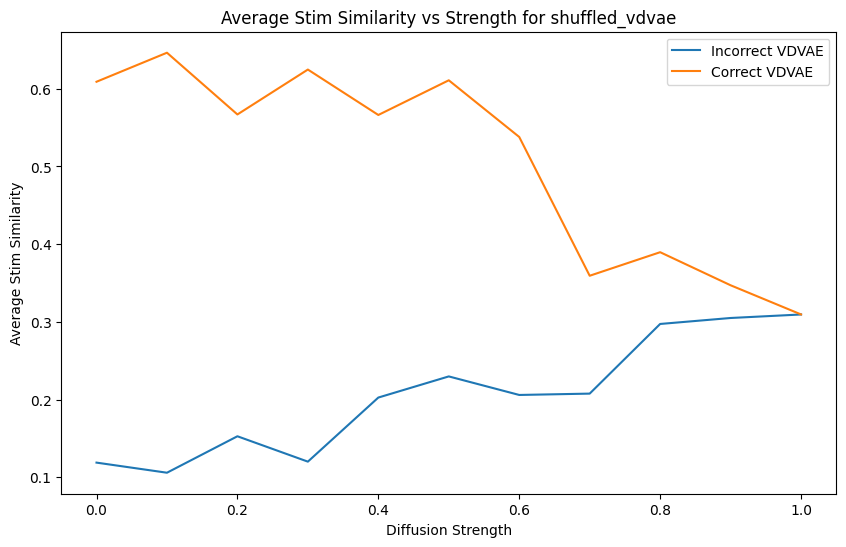

In [7]:

# Load filtered responses
filtered_df = pd.read_csv(f'{dataframe_path}filtered_stimuli_responses_v{response_version}.csv')
filtered_df.head()
# filtered_df = pd.read_csv(f'{dataframe_path}filtered_responses_v{response_version}.csv')
# df = pd.read_csv(f'{dataframe_path}calibration_responses_v{response_version}.csv')
df_experiment = pd.read_csv(dataframe_path + f"experiment_v{experiment_version}.csv")

df_responses = pd.read_csv(f"{response_path}annotations_v{response_version}.csv")


# Now, let's group the data by 'stim_str' and 'shuffled_vdvae', and calculate the average 'stim_similarity'
grouped_df = filtered_df.groupby(['stimulus_str', 'shuffle_vdvae'])['y'].mean().reset_index()
# Create the plot
plt.figure(figsize=(10, 6))

# Plot for shuffled_vdvae == True
plt.plot(grouped_df[grouped_df['shuffle_vdvae'] == True]['stimulus_str'], 
         grouped_df[grouped_df['shuffle_vdvae'] == True]['y'], 
         label='Incorrect VDVAE')

# Plot for shuffled_vdvae == False
plt.plot(grouped_df[grouped_df['shuffle_vdvae'] == False]['stimulus_str'], 
         grouped_df[grouped_df['shuffle_vdvae'] == False]['y'], 
         label='Correct VDVAE')

# Adding labels and title
plt.xlabel('Diffusion Strength')
plt.ylabel('Average Stim Similarity')
plt.title('Average Stim Similarity vs Strength for shuffled_vdvae')
plt.legend()

# Show the plot
plt.show()


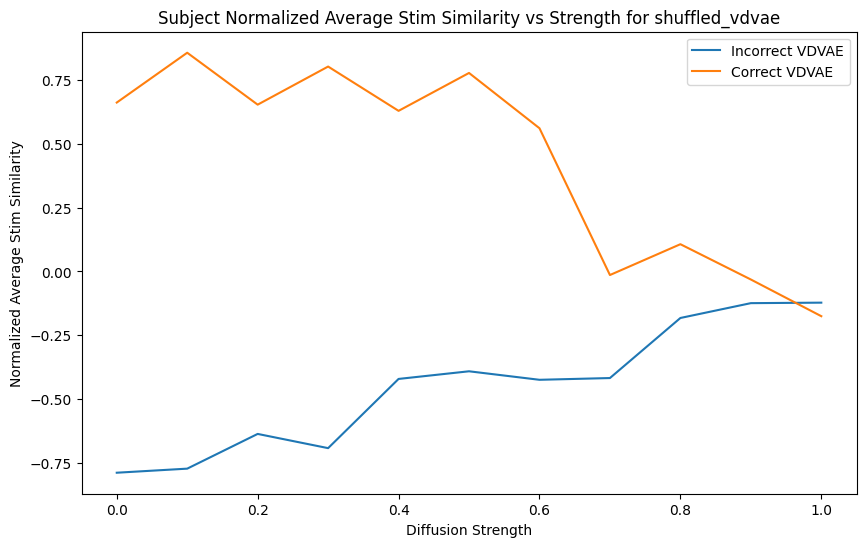

In [12]:
# Normalize values within each subject (participant)
filtered_df = pd.read_csv(f'{dataframe_path}filtered_stimuli_responses_v{response_version}.csv')
filtered_df['y_normalized'] = filtered_df.groupby('participant')['y'].transform(lambda x: (x - x.mean()) / x.std())

# Group the data by 'stimulus_str' and 'shuffle_vdvae', and calculate the average 'y_normalized'
grouped_df_normalized = filtered_df.groupby(['stimulus_str', 'shuffle_vdvae'])['y_normalized'].mean().reset_index()

# Create the plot
plt.figure(figsize=(10, 6))

# Plot for shuffled_vdvae == True
plt.plot(grouped_df_normalized[grouped_df_normalized['shuffle_vdvae'] == True]['stimulus_str'],
         grouped_df_normalized[grouped_df_normalized['shuffle_vdvae'] == True]['y_normalized'],
         label='Incorrect VDVAE')

# Plot for shuffled_vdvae == False
plt.plot(grouped_df_normalized[grouped_df_normalized['shuffle_vdvae'] == False]['stimulus_str'],
         grouped_df_normalized[grouped_df_normalized['shuffle_vdvae'] == False]['y_normalized'],
         label='Correct VDVAE')

# Adding labels and title
plt.xlabel('Diffusion Strength')
plt.ylabel('Normalized Average Stim Similarity')
plt.title('Subject Normalized Average Stim Similarity vs Strength for shuffled_vdvae')
plt.legend()

# Show the plot
plt.show()


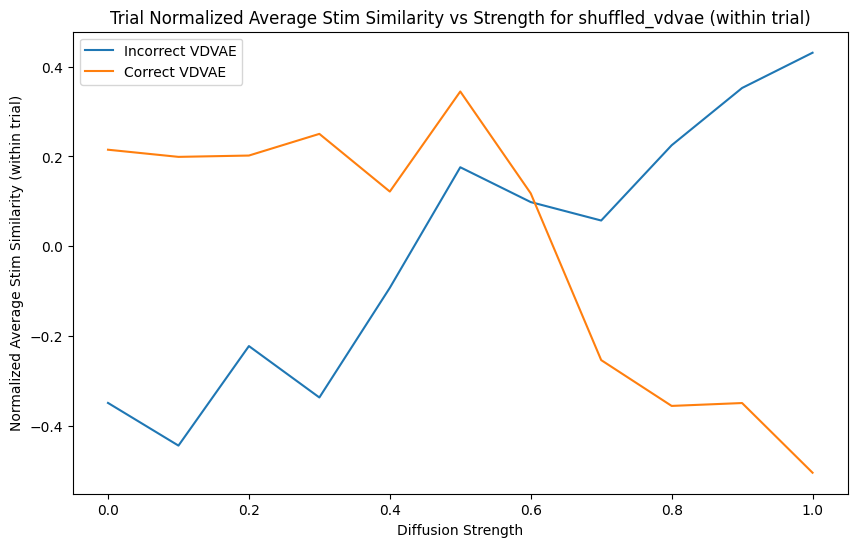

In [13]:
# Normalize values within each trial (stimulus_str and participant combination)
filtered_df = pd.read_csv(f'{dataframe_path}filtered_stimuli_responses_v{response_version}.csv')
filtered_df['y_normalized_trial'] = filtered_df.groupby(['trial', 'participant'])['y'].transform(lambda x: (x - x.mean()) / x.std())

# Group the data by 'stimulus_str' and 'shuffle_vdvae', and calculate the average 'y_normalized_trial'
grouped_df_normalized_trial = filtered_df.groupby(['stimulus_str', 'shuffle_vdvae'])['y_normalized_trial'].mean().reset_index()

# Create the plot
plt.figure(figsize=(10, 6))

# Plot for shuffled_vdvae == True
plt.plot(grouped_df_normalized_trial[grouped_df_normalized_trial['shuffle_vdvae'] == True]['stimulus_str'],
         grouped_df_normalized_trial[grouped_df_normalized_trial['shuffle_vdvae'] == True]['y_normalized_trial'],
         label='Incorrect VDVAE')

# Plot for shuffled_vdvae == False
plt.plot(grouped_df_normalized_trial[grouped_df_normalized_trial['shuffle_vdvae'] == False]['stimulus_str'],
         grouped_df_normalized_trial[grouped_df_normalized_trial['shuffle_vdvae'] == False]['y_normalized_trial'],
         label='Correct VDVAE')

# Adding labels and title
plt.xlabel('Diffusion Strength')
plt.ylabel('Normalized Average Stim Similarity (within trial)')
plt.title('Trial Normalized Average Stim Similarity vs Strength for shuffled_vdvae (within trial)')
plt.legend()

# Show the plot
plt.show()


/tmp/ipykernel_17103/2934534834.py:22: FutureWarning: In a future version, object-dtype columns with all-bool values will not be included in reductions with bool_only=True. Explicitly cast to bool dtype instead.
  delta_df = pd.concat([delta_df, pd.DataFrame({'shuffle_vdvae': [shuffle_vdvae],
/tmp/ipykernel_17103/2934534834.py:22: FutureWarning: In a future version, object-dtype columns with all-bool values will not be included in reductions with bool_only=True. Explicitly cast to bool dtype instead.
  delta_df = pd.concat([delta_df, pd.DataFrame({'shuffle_vdvae': [shuffle_vdvae],
/tmp/ipykernel_17103/2934534834.py:22: FutureWarning: In a future version, object-dtype columns with all-bool values will not be included in reductions with bool_only=True. Explicitly cast to bool dtype instead.
  delta_df = pd.concat([delta_df, pd.DataFrame({'shuffle_vdvae': [shuffle_vdvae],
/tmp/ipykernel_17103/2934534834.py:22: FutureWarning: In a future version, object-dtype columns with all-bool values w

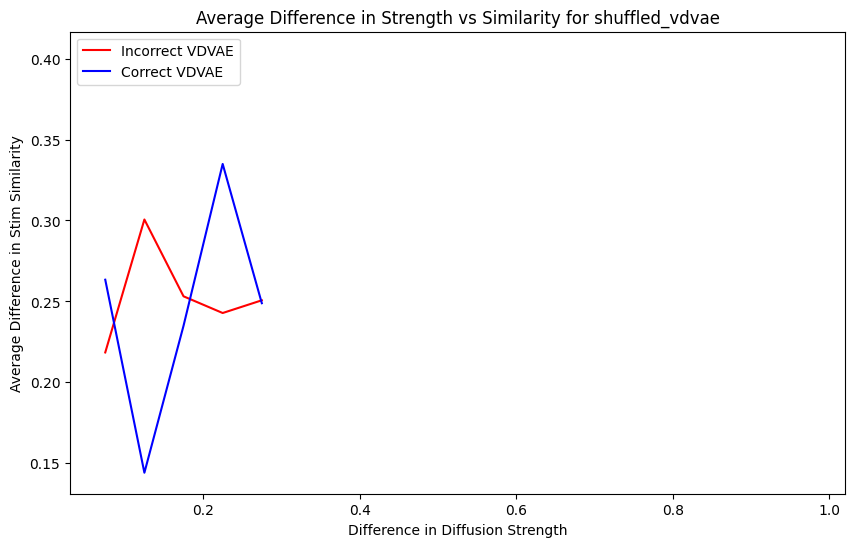

In [20]:
from itertools import combinations
filtered_df = pd.read_csv(f'{dataframe_path}filtered_stimuli_responses_v{response_version}.csv')
# Normalize values within each trial (grouping by 'trial' and 'participant')
filtered_df['y_normalized_trial'] = filtered_df.groupby(['trial', 'participant'])['y'].transform(lambda x: (x - x.mean()) / x.std())

# Create an empty DataFrame to store deltas
delta_df = pd.DataFrame(columns=['shuffle_vdvae', 'delta_strength', 'delta_similarity'])

# Iterate through each unique trial and participant
for (trial, participant), group in filtered_df.groupby(['trial', 'participant']):
    if len(group) == 3:
        # Get all unique pairs of the 3 stimuli
        pairs = list(combinations(group.index, 2))

        # Calculate deltas for each pair
        for idx1, idx2 in pairs:
            delta_strength = abs(group.loc[idx1, 'stimulus_str'] - group.loc[idx2, 'stimulus_str'])
            delta_similarity = abs(group.loc[idx1, 'y'] - group.loc[idx2, 'y'])
            shuffle_vdvae = group.loc[idx1, 'shuffle_vdvae']  # All values in a group should have the same 'shuffle_vdvae'

            # Append deltas to the DataFrame
            delta_df = pd.concat([delta_df, pd.DataFrame({'shuffle_vdvae': [shuffle_vdvae],
                                                          'delta_strength': [delta_strength],
                                                          'delta_similarity': [delta_similarity]})], ignore_index=True)

# Group by the bins and 'shuffle_vdvae', then calculate the mean of delta_similarity
delta_df['delta_str_normalized'] = delta_df.groupby(['delta_strength', 'shuffle_vdvae'])['delta_similarity'].transform(lambda x: (x - x.mean()) / x.std())
# Split the DataFrame based on 'shuffle_vdvae' values
grouped_df_normalized_trial = delta_df.groupby(['delta_strength', 'shuffle_vdvae'])['delta_str_normalized'].mean().reset_index()

# Create the plot
plt.figure(figsize=(10, 6))

# Plot for shuffled_vdvae == True
plt.plot(grouped_df_normalized_trial[grouped_df_normalized_trial['shuffle_vdvae'] == True]['delta_strength'],
         grouped_df_normalized_trial[grouped_df_normalized_trial['shuffle_vdvae'] == True]['delta_str_normalized'],
         label='Incorrect VDVAE')

# Plot for shuffled_vdvae == False
plt.plot(grouped_df_normalized_trial[grouped_df_normalized_trial['shuffle_vdvae'] == False]['delta_strength'],
         grouped_df_normalized_trial[grouped_df_normalized_trial['shuffle_vdvae'] == False]['delta_str_normalized'],
         label='Correct VDVAE')

# Adding labels and title
plt.xlabel('Difference in Diffusion Strength')
plt.ylabel('Difference in Stim Similarity')
plt.title('Relationship between Difference in Strength and Similarity for shuffled_vdvae')
plt.legend()

# Show the plot
plt.show()

In [9]:
import pandas as pd
import json
from collections import defaultdict

# Load the JSON data again
file_path = f'{response_path}deployment_v{response_version}_tree.json'

with open(file_path, 'r') as file:
    data = json.load(file)

# Function to determine Email Consent value
def get_email_consent(value):
    if isinstance(value, str):
        if "yes" in value.lower():
            return True
        elif "no" in value.lower():
            return False
    return False  # Default to False if not explicitly "yes"

# Dictionary to track unique participants and number of sessions
participant_sessions = defaultdict(int)
participant_email_consent = defaultdict(bool)

# List to store data for CSV
csv_data = []

# Iterate over the high-level session entries
for participant_id, session_data in data.items():
    tasks = session_data.get('tasks', [])
    # Ensure all tasks have "finished" status
    if all(task.get('status') == 'finished' for task in tasks):
        csv_data.append({
            "anonymous participant ID": participant_id,
            "num_sessions": 1
        })

# Create a DataFrame and write the CSV data
csv_df = pd.DataFrame(csv_data)
csv_df["Consented"] = True
csv_file_path = f'{response_path}participant_info_v{response_version}.csv'
csv_df.to_csv(csv_file_path, index=False)